# 08 · H1-WR confirmatory analysis (sole primary hypothesis)

This notebook **only displays** the result of the single registered run produced by `scripts/run_h1_wr_confirmatory.py`. No model is refitted here.

**Registered specification** (preregistration §2, §6, §8–§12; deviations D1–D4):
- **Model:** REML bivariate-context linear mixed model.
- **Inference:** full REML player-cluster percentile bootstrap, B = 2,000.
- **Decision:** supported iff Δ̂ > 0, the 95 % CI excludes 0, and the 2025 season-forward estimate has the same sign.
- **Falsified** iff the 90 % CI upper bound is < 0.15, or the 95 % CI lies entirely below 0.
- **Otherwise:** inconclusive.

H2, DB, DL and OL have **not** been analysed.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from nfl_bdb.visualization import style
style.apply(); pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(60)
import os
OUT = Path(os.environ['H1_OUT']) if os.environ.get('H1_OUT') else ROOT / 'experiments/h1_wr_confirmatory' / (ROOT / 'experiments/h1_wr_confirmatory/LATEST').read_text().strip()
RUN = OUT.name
R = json.load(open(OUT / 'h1_wr_result.json'))
boot = np.load(OUT / 'bootstrap_delta.npy'); jack = np.load(OUT / 'jackknife_delta.npy')
print('run', RUN, '| code commit', R['code_commit'], '| join', R['join_run'], '| seed', R['seed'], '| B', R['B'])
print('DECISION:', R['decision'])

run 20261121T223645Z | code commit 8674e8038a3f32b7ee3ff56ee7c3742915cca3f0 | join 20261121T135032Z | seed 4004 | B 2000
DECISION: INCONCLUSIVE


## 1. Primary result

In [2]:
P = R['primary']
pl.DataFrame([dict(quantity=k, value=str(v)) for k, v in [
    ('Δ̂ = ρ_deep − ρ_short (REML)', round(P['delta'], 4)), ('ρ_deep', round(P['rho_deep'], 4)), ('ρ_short', round(P['rho_short'], 4)),
    ('95% percentile CI', [round(v, 4) for v in P['ci95_percentile']]), ('90% percentile CI', [round(v, 4) for v in P['ci90_percentile']]),
    ('bootstrap SE', round(P['se_boot'], 4)), ('two-sided bootstrap p', round(P['p_two_sided'], 4)),
    ('Δ̂ > 0', P['delta_positive']), ('95% CI excludes 0 (positive)', P['ci_excludes_0_positive']),
    ('2025 season-forward Δ̂', round(P['season_forward']['delta_2025'], 4)), ('season-forward same sign', P['season_forward_same_sign']),
    ('falsified: 90% upper < 0.15', P['falsification']['ci90_upper_below_sesoi']), ('falsified: 95% CI < 0', P['falsification']['ci95_entirely_below_0']),
    ('DECISION', R['decision'])]])

quantity,value
str,str
"""Δ̂ = ρ_deep − ρ_short (REML)""","""0.09"""
"""ρ_deep""","""0.5759"""
"""ρ_short""","""0.4859"""
"""95% percentile CI""","""[-0.0886, 0.4001]"""
"""90% percentile CI""","""[-0.0452, 0.333]"""
"""bootstrap SE""","""0.1225"""
"""two-sided bootstrap p""","""0.211"""
"""Δ̂ > 0""","""True"""
"""95% CI excludes 0 (positive)""","""False"""


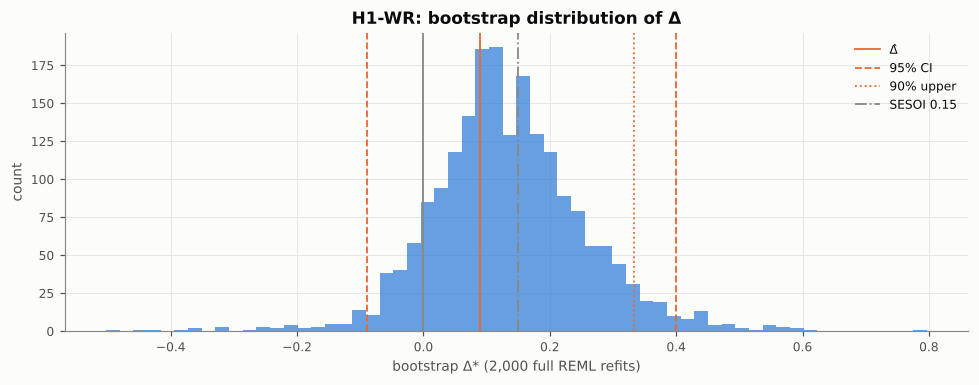

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(boot, bins=60, color=style.SERIES[0], alpha=0.7)
for v, ls, lab in [(P['delta'], '-', 'Δ̂'), (P['ci95_percentile'][0], '--', '95% CI'), (P['ci95_percentile'][1], '--', None),
                   (P['ci90_percentile'][1], ':', '90% upper'), (0.15, '-.', 'SESOI 0.15'), (0, '-', None)]:
    ax.axvline(v, ls=ls, color=style.MUTED if v in (0, 0.15) else style.SERIES[1], lw=1.2, label=lab)
ax.set_xlabel('bootstrap Δ* (2,000 full REML refits)'); ax.set_ylabel('count'); ax.legend(); ax.set_title('H1-WR: bootstrap distribution of Δ')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h1_wr_bootstrap.png', dpi=150); plt.show()

## 2. Sample and observations per context

In [4]:
S = R['sample']
print('players', S['players'], '| plays', S['plays'], '| team-seasons', R['diagnostics']['team_seasons'],
      '(single-player team-seasons', R['diagnostics']['team_seasons_single_player'], ')')
display(pl.DataFrame(S['by_context'])); display(pl.DataFrame(S['plays_per_player_context'])); pl.DataFrame(S['seasons'])

players 57 | plays 19960 | team-seasons 71 (single-player team-seasons 36 )


ctx,plays,players
str,i64,i64
"""deep""",9961,57
"""short""",9999,57


ctx,min,median,max
str,i64,f64,i64
"""deep""",47,141.0,575
"""short""",31,144.0,528


season,plays,players
i64,i64,i64
2023,3851,24
2024,7245,39
2025,8864,51


## 3. Convergence and diagnostics

In [5]:
D = R['diagnostics']; Bt = R['bootstrap']
print(json.dumps({k: D[k] for k in ('converged', 'sigma_b', 'corr_b', 's2_team', 's2_resid', 'fixed_effect_columns', 'reliability_player_context_mean')}, indent=1))
print('bootstrap refits OK:', Bt['n_ok'], 'failed:', Bt['n_failed'], '| boot mean', round(Bt['mean'], 4), 'sd', round(Bt['sd'], 4),
      '| median − Δ̂', round(Bt['median_minus_estimate'], 4))
print('season-forward fit:', P['season_forward'])
print('seconds:', R['seconds'])

{
 "converged": true,
 "sigma_b": [
  [
   0.0352660879317651,
   0.03014569235375155
  ],
  [
   0.03014569235375155,
   0.060038473583990934
  ]
 ],
 "corr_b": 0.6551365035980283,
 "s2_team": 0.009886173131091958,
 "s2_resid": [
  0.762963011545771,
  1.4527898859634922
 ],
 "fixed_effect_columns": 56,
 "reliability_player_context_mean": [
  0.848060693193305,
  0.8196908703629329
 ]
}
bootstrap refits OK: 2000 failed: 0 | boot mean 0.1341 sd 0.1225 | median − Δ̂ 0.035
season-forward fit: {'delta_2025': 0.21903877251676285, 'rho_2025': [0.6682960633818348, 0.44925729086507193], 'n_players_2025': 46, 'n_plays_2025': 8745, 'converged': True}
seconds: {'primary': 656.2705085277557, 'total': 679.0521078109741}


## 4. Registered accompanying reports (none affects the decision)

In [6]:
E = R['effect_size']; M = R['cross_check_moment']; Bc = R['bca']; By = R['bayes_sensitivity']
print('BCa 95%:', [round(v, 4) for v in Bc['ci']['0.95']], '| BCa 90%:', [round(v, 4) for v in Bc['ci']['0.9']], '| z0', round(Bc['z0'], 3), 'a', round(Bc['acceleration'], 4))
print('raw slopes (yd/s of game speed per 0.25 yd/s combine peak): deep %.3f, short %.3f' % tuple(E['raw_slope_per_0_25_yds']))
display(pl.DataFrame([dict(R_x=k, **v) for k, v in E['disattenuated'].items()]))
print('moment cross-check (spec §1.2, never decisive): Δ =', round(M['delta'], 4), 'ρ =', [round(v, 4) for v in M['rho']], '| disagrees by > SE/2:', M['disagrees_by_more_than_half_se'])
print('Bayesian sensitivity (prior N(0, 0.15²)): posterior mean %.3f, sd %.3f, P(Δ>0) %.3f, P(Δ>0.15) %.3f' %
      (By['posterior_mean'], By['posterior_sd'], By['p_delta_gt_0'], By['p_delta_gt_sesoi']))

BCa 95%: [-0.2841, 0.2827] | BCa 90%: [-0.1789, 0.2352] | z0 -0.368 a 0.0132
raw slopes (yd/s of game speed per 0.25 yd/s combine peak): deep 0.110, short 0.113


R_x,rho_deep,rho_short,delta
str,f64,f64,f64
"""registered_pooled""",0.579681,0.489137,0.090544
"""within_WR_D3""",0.593997,0.501216,0.09278


moment cross-check (spec §1.2, never decisive): Δ = 0.0717 ρ = [0.5265, 0.4547] | disagrees by > SE/2: False
Bayesian sensitivity (prior N(0, 0.15²)): posterior mean 0.054, sd 0.095, P(Δ>0) 0.715, P(Δ>0.15) 0.156


## 5. Interpretation

See `research_notes/h1_wr_confirmatory_results.md`.